In [26]:
import pandas as pd
import numpy as np

In [27]:
df = pd.read_csv("sales_data.csv")

In [28]:
print(df.columns)
print(df.head(5))
print(df.tail(5))
print(df.dtypes)

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality',
       'Epidemic', 'Demand'],
      dtype='str')
         Date Store ID Product ID     Category Region  Inventory Level  \
0  2022-01-01     S001      P0001  Electronics  North              195   
1  2022-01-01     S001      P0002     Clothing  North              117   
2  2022-01-01     S001      P0003     Clothing  North              247   
3  2022-01-01     S001      P0004  Electronics  North              139   
4  2022-01-01     S001      P0005    Groceries  North              152   

   Units Sold  Units Ordered  Price  Discount Weather Condition  Promotion  \
0         102            252  72.72         5             Snowy          0   
1         117            249  80.16        15             Snowy          1   
2         114            612  62.94        10        

In [29]:
print(df.isnull().sum())

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64


In [30]:
df['Date'] =pd.to_datetime(df['Date'])
df['Category'] = df['Category'].astype('category')
df['Region'] = df['Region'].astype('category')
df['Weather Condition'] = df['Weather Condition'].astype('category')
df['Seasonality'] = df['Seasonality'].astype('category')
print(df.dtypes)


Date                  datetime64[us]
Store ID                         str
Product ID                       str
Category                    category
Region                      category
Inventory Level                int64
Units Sold                     int64
Units Ordered                  int64
Price                        float64
Discount                       int64
Weather Condition           category
Promotion                      int64
Competitor Pricing           float64
Seasonality                 category
Epidemic                       int64
Demand                         int64
dtype: object


 Regression model for how much do price, discount and competitor price change units sold

In [31]:
# test train split and model making
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

x = df[['Price','Discount','Competitor Pricing']]
y=df['Units Sold']
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.3,random_state=0)

lm1 = LinearRegression()
lm1.fit(x_train,y_train)
y_pred1 = lm1.predict(x_test)
score1 = r2_score(y_test,y_pred1)
print(score1)

0.03128227183068677


so here we can see that this model score only 31% approx so the x variables are not enough to define the units solde so we will try one more time by adding more variable to x to see if adding more will result in a higher score or not

In [32]:
x = df[['Price','Demand','Inventory Level']]
y=df['Units Sold']
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.3,random_state=0)

lm2 = LinearRegression()
lm2.fit(x_train,y_train)
y_pred2 = lm2.predict(x_test)
score2 = r2_score(y_test,y_pred2)
print(score2)

0.713858684900633


hence here we can see that i added two more variables promotion, demand, Inventory Level and i also removed 'Competitor Pricing','Discount','Discount' and the score is now increased  to 70% which means these variable factors are defining this uits sold with 72% which is really a good score.

MODEL 2 - Time series forecasting (ARIMA, SARIMAX , Prophet) in regarding to predict units sold in relation to the category 'Clothing' and the store id (5002)

In [33]:
# ARIMA & SARIMAX & HOLT WINTER METHOD
store_id = 'S001' 
category_name = 'Clothing'

filtered_df = df[(df['Store ID'] == 'S002') & (df['Category'] == 'Clothing')]

# 4. Aggregate units sold by date (if there are multiple products per day)
ts_df = filtered_df.groupby('Date')['Units Sold'].sum()
print(ts_df.head(5))
# Resample to weekly frequency (sums units sold every week)
weekly_sales = ts_df.resample('w').sum()

print("Weekly Sales:")
print(weekly_sales.head(5))

#test train split 
train_data = weekly_sales.iloc[:-6]
test_data = weekly_sales.iloc[-6:]

print(f"Training data points: {len(train_data)}")
print(f"Test data points: {len(test_data)}")

Date
2022-01-01    413
2022-01-02    292
2022-01-03    365
2022-01-04    396
2022-01-05    539
Name: Units Sold, dtype: int64
Weekly Sales:
Date
2022-01-02     705
2022-01-09    3504
2022-01-16    3675
2022-01-23    3544
2022-01-30    3563
Freq: W-SUN, Name: Units Sold, dtype: int64
Training data points: 104
Test data points: 6


C:\Users\HP\AppData\Local\Temp\ipykernel_29496\2800591289.py:11: Pandas4Warning: 'w' is deprecated and will be removed in a future version, please use 'W' instead.
  weekly_sales = ts_df.resample('w').sum()


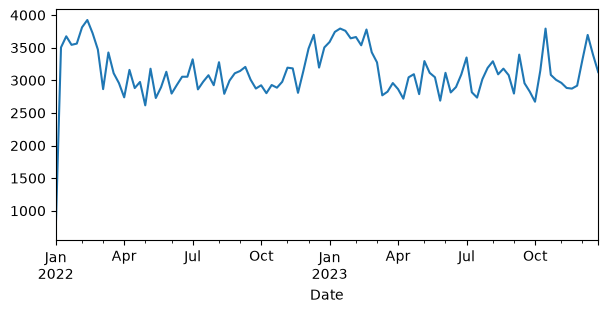

In [34]:
import matplotlib.pyplot as plt
train_data.plot(figsize=(7,3))
plt.show()

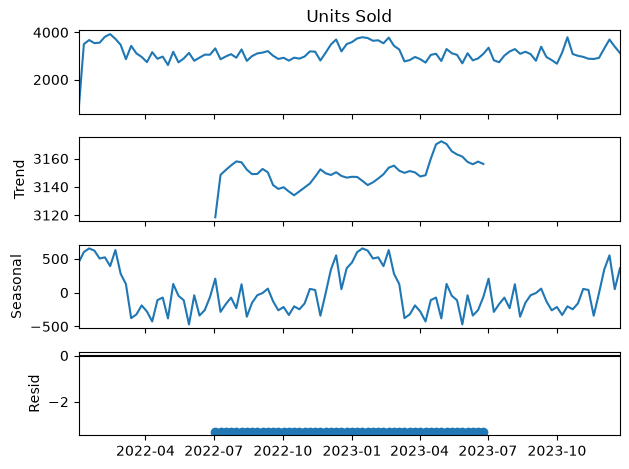

In [35]:
#additive decomposition
from statsmodels.tsa.seasonal import seasonal_decompose
r_d= seasonal_decompose(train_data,model='additive',period= 52)
r_d.plot()
plt.show()

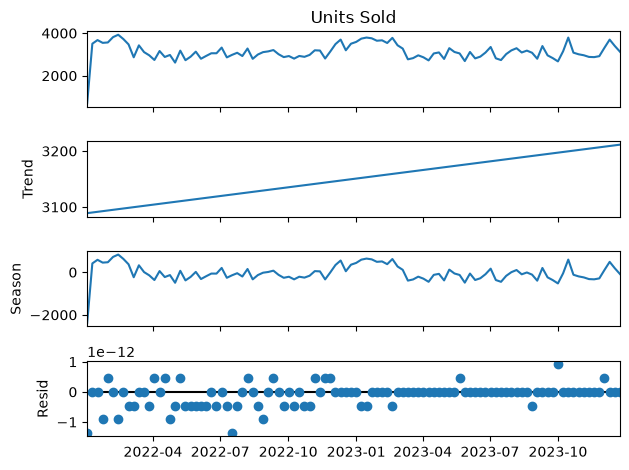

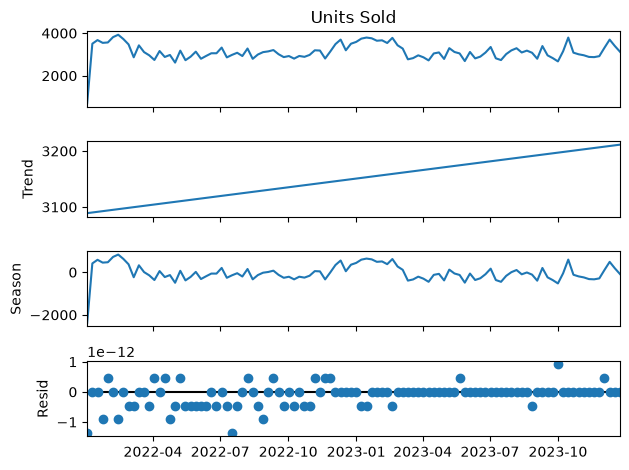

In [36]:

from statsmodels.tsa.seasonal import STL
stl=STL(train_data,period=52)
result=stl.fit()
result.plot()

here u caN see that i have applied both classical or modern stl decompostion for additive decompostion and here we can see tat the STL is far better then classical as it smothens the graph and gives more clear pciture so now next we move ahed as we will check weather out ts_df data is stationary or not by testing our data with ADF & KPSS

In [37]:
#ADF Testing
from statsmodels.tsa.stattools import adfuller
result_adf = adfuller(train_data)
print("ADF STATISTIC;",result_adf[0])
print("P_Value;",result_adf[1])
print("Critical Values;",result_adf[4])

ADF STATISTIC; -9.259282455687286
P_Value; 1.4214932083285938e-15
Critical Values; {'1%': np.float64(-3.4954932834550623), '5%': np.float64(-2.8900369024285117), '10%': np.float64(-2.5819706975209726)}


In [38]:
# KPSS Testing
from statsmodels.tsa.stattools import kpss
result_kpss =kpss(train_data,regression='c')
print("KPSS STATISTIC;",result_kpss[0])
print("P_Value;",result_kpss[1])

KPSS STATISTIC; 0.07256326068525963
P_Value; 0.1


C:\Users\HP\AppData\Local\Temp\ipykernel_29496\2638487206.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result_kpss =kpss(train_data,regression='c')


Well now our data is stationary becauase 
ADF Test: Rejected non-stationarity (p = 1.42 \times 10^{-15} < 0.05) — Indicates Stationary.
KPSS Test: Failed to reject stationarity (p = 0.10 > 0.05) — Indicates Stationary.
so now we move towards the next step which is making the twi models which is finding the p,d,q values by ACF and PACF and then make ARIMA & SARIMAX  & HOLT Winters Method (Tripple Exp Smoothing) models

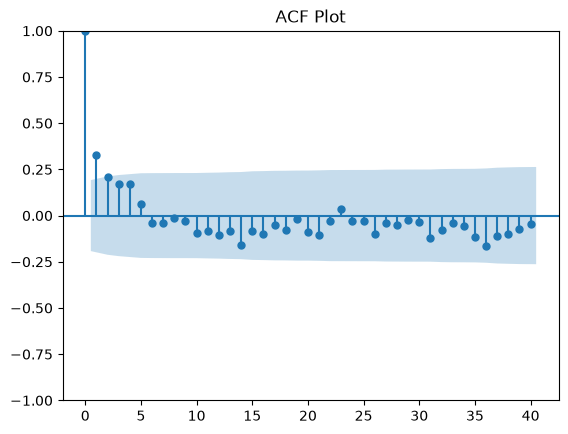

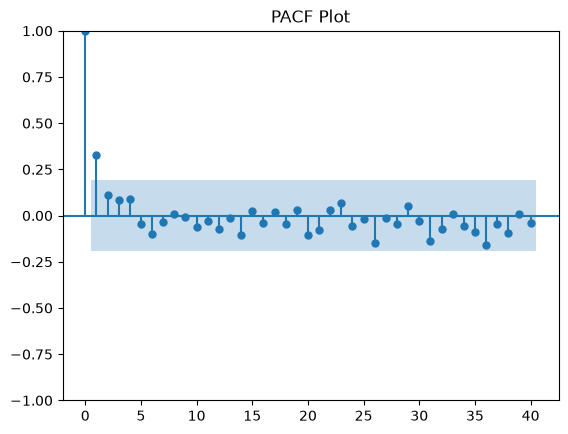

In [39]:
#ACF
from statsmodels.graphics.tsaplots import plot_acf , plot_pacf
plot_acf(train_data,lags=40)
plt.title("ACF Plot")
plt.show()

plot_pacf(train_data,lags=40)
plt.title("PACF Plot")
plt.show()

by seeing the graph wee are picking p,d,q as 1,0,1 for our models

In [40]:
#ARIMA MODEL
from statsmodels.tsa.arima.model import ARIMA
arima_model = ARIMA (train_data,order=(1,0,1))
arima_model_fit = arima_model.fit()
print(arima_model_fit.summary())
forecast_arima = arima_model_fit.forecast(steps=6)
print(forecast_arima)

                               SARIMAX Results                                
Dep. Variable:             Units Sold   No. Observations:                  104
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -760.155
Date:                Tue, 20 Oct 2026   AIC                           1528.309
Time:                        20:58:50   BIC                           1538.887
Sample:                    01-02-2022   HQIC                          1532.595
                         - 12-24-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       3097.5346     92.963     33.320      0.000    2915.331    3279.738
ar.L1          0.5535      0.146      3.781      0.000       0.267       0.840
ma.L1         -0.0685      0.185     -0.371      0.7

In [41]:
#SARIMAX Model
from statsmodels.tsa.statespace.sarimax import SARIMAX
sarimax_model = SARIMAX (train_data,order=(1,0,1),seasonal_order=(1,0,1,52))
sarimax_model_fit = sarimax_model.fit()
print(sarimax_model_fit.summary())
forecast_sarimax = sarimax_model_fit.forecast(steps=6)
print(forecast_sarimax)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


                                     SARIMAX Results                                      
Dep. Variable:                         Units Sold   No. Observations:                  104
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 52)   Log Likelihood                -766.907
Date:                            Tue, 20 Oct 2026   AIC                           1543.813
Time:                                    20:58:53   BIC                           1557.035
Sample:                                01-02-2022   HQIC                          1549.170
                                     - 12-24-2023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9964      0.006    154.752      0.000       0.984       1.009
ma.L1         -0.4623      0.062   

In [42]:
# Holt WInters method (Tripple exp smoothing) MODEL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
holt_model = ExponentialSmoothing(train_data,trend='add',seasonal='add',seasonal_periods=52)
holt_model_fit = holt_model.fit()
forecast_holt_model = holt_model_fit.forecast(steps=6)
print(forecast_holt_model)

2023-12-31    2477.153943
2024-01-07    3956.874779
2024-01-14    4062.456418
2024-01-21    3967.261009
2024-01-28    3914.397495
2024-02-04    4052.714469
Freq: W-SUN, dtype: float64


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


Now we have made all three models ARIMA SARIMAX AND HOLT WINTER METHOD buyt now its time to check their healt like how well theya re performing so for that we are gping to use 3 methods to cehck which are RMSE , MSE & WMAPE.

In [43]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. EVALUATE ARIMA MODEL ---
arima_rmse = np.sqrt(mean_squared_error(test_data, forecast_arima))
arima_mae = mean_absolute_error(test_data, forecast_arima)
arima_wmape = np.sum(np.abs(test_data - forecast_arima)) / np.sum(test_data) * 100

print("=== ARIMA(1,0,1) ===")
print(f"RMSE:  {arima_rmse:.2f}")
print(f"MAE:   {arima_mae:.2f}")
print(f"WMAPE: {arima_wmape:.2f}%\n")


# --- 2. EVALUATE SARIMAX MODEL ---
sarimax_rmse = np.sqrt(mean_squared_error(test_data, forecast_sarimax))
sarimax_mae = mean_absolute_error(test_data, forecast_sarimax)
sarimax_wmape = np.sum(np.abs(test_data - forecast_sarimax)) / np.sum(test_data) * 100

print("=== SARIMAX(1,0,1)(1,0,1,52) ===")
print(f"RMSE:  {sarimax_rmse:.2f}")
print(f"MAE:   {sarimax_mae:.2f}")
print(f"WMAPE: {sarimax_wmape:.2f}%\n")


# --- 3. EVALUATE HOLT-WINTERS MODEL ---
hw_rmse = np.sqrt(mean_squared_error(test_data, forecast_holt_model))
hw_mae = mean_absolute_error(test_data, forecast_holt_model)
hw_wmape = np.sum(np.abs(test_data - forecast_holt_model)) / np.sum(test_data) * 100

print("=== Holt-Winters ===")
print(f"RMSE:  {hw_rmse:.2f}")
print(f"MAE:   {hw_mae:.2f}")
print(f"WMAPE: {hw_wmape:.2f}%")


=== ARIMA(1,0,1) ===
RMSE:  1010.02
MAE:   758.40
WMAPE: 24.56%

=== SARIMAX(1,0,1)(1,0,1,52) ===
RMSE:  970.71
MAE:   702.05
WMAPE: 22.74%

=== Holt-Winters ===
RMSE:  1426.61
MAE:   990.93
WMAPE: 32.09%


So here we can see that thw WMAPE is the lowest in the SARIMAX Model so it is telling best percentage accuracy among other models so we are going to deploy SARIMAX.

and now we are merging test and train split back to the our df so that we can properly make SARIMAX Model on in and forecast it acordingly and this is going to be the last step and after that we are jsut done with everything with the Time Series Forecasting Pipeline.

In [44]:
# 1. Combine train and test into one full dataset
full_data = pd.concat([train_data, test_data])

# Ensure the index has explicit weekly frequency ('W')
full_data.index = pd.DatetimeIndex(full_data.index, freq='W')

print(f"Total historical weekly data points: {len(full_data)}")

# 2. Refit the SARIMAX model on 100% of the weekly data
final_model = SARIMAX(
    full_data, 
    order=(1, 0, 1), 
    seasonal_order=(1, 0, 1, 52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_model_fit = final_model.fit()
print("SARIMAX successfully refitted on full weekly dataset!")

# 3. Generate future operational forecasts (e.g., next 12 weeks)
future_steps = 12
future_forecast = final_model_fit.forecast(steps=future_steps)

print("\n=== Upcoming 12-Week Weekly Sales Forecast ===")
print(future_forecast)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


Total historical weekly data points: 110
SARIMAX successfully refitted on full weekly dataset!

=== Upcoming 12-Week Weekly Sales Forecast ===
2024-02-11    2984.717082
2024-02-18    3109.326757
2024-02-25    2922.693703
2024-03-03    2848.173841
2024-03-10    2558.063482
2024-03-17    2587.722618
2024-03-24    2653.079664
2024-03-31    2601.489942
2024-04-07    2505.158650
2024-04-14    2677.325019
2024-04-21    2692.129045
2024-04-28    2531.891263
Freq: W-SUN, Name: predicted_mean, dtype: float64


So this is our full forecasting and this pipeline is now completed so we will move forward.

So as now we have done our time series forecasting with models like arima sarimax etc but now there is a new mehod of time seris forecasting known ans PROPHET by Meta Facebook so it is a very quick and a good way to do time series forecasting and as it also a new so it really be more accurate and give details more then just showing the forecasting units so lets perform that

In [45]:
print(full_data.head(5))

Date
2022-01-02     705
2022-01-09    3504
2022-01-16    3675
2022-01-23    3544
2022-01-30    3563
Freq: W-SUN, Name: Units Sold, dtype: int64


In [46]:
#PROPHET MODEL
from prophet import Prophet
# we are converting that dataset into regular column
prophet_df = full_data.reset_index()
# now we changing the names of the columns to ds and y
prophet_df = prophet_df[['Date', 'Units Sold']].rename(columns={'Date': 'ds', 'Units Sold': 'y'})
# now we do train test split
train_size = int(len(prophet_df) * 0.8)   
train_df1 = prophet_df.iloc[:train_size]
test_df1 = prophet_df.iloc[train_size:]
# now Building PROPHET  Model
model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, seasonality_mode='additive')
#model fit
model.fit(train_df1)
#making future dataframe
prophet_future = model.make_future_dataframe(periods=len(test_df1), freq='W')
prophet_pred = model.predict(prophet_future)
forecast_prophet = prophet_pred[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(len(test_df1))
print(forecast_prophet)




Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
20:58:56 - cmdstanpy - INFO - Chain [1] start processing
20:58:57 - cmdstanpy - INFO - Chain [1] done processing


            ds         yhat   yhat_lower   yhat_upper
88  2023-09-10  3148.231145  2746.239303  3545.706449
89  2023-09-17  3216.135554  2857.714461  3601.637382
90  2023-09-24  3145.717202  2748.475137  3528.607229
91  2023-10-01  2960.122448  2569.180479  3346.672548
92  2023-10-08  2827.213313  2444.099340  3200.989591
93  2023-10-15  2890.071927  2485.140394  3287.642907
94  2023-10-22  3098.085681  2697.305985  3484.215550
95  2023-10-29  3243.951668  2838.654174  3630.136235
96  2023-11-05  3190.896514  2809.631699  3611.484922
97  2023-11-12  3041.193796  2629.782755  3420.502064
98  2023-11-19  3037.296202  2648.934434  3406.212687
99  2023-11-26  3283.592962  2858.841021  3677.514175
100 2023-12-03  3598.579323  3208.880714  3962.310494
101 2023-12-10  3682.711760  3267.028383  4056.311117
102 2023-12-17  3437.159170  3045.168876  3834.198377
103 2023-12-24  3087.524900  2703.902921  3496.597411
104 2023-12-31  2970.353511  2597.086784  3381.103662
105 2024-01-07  3206.841008 

The prediction has been done on the train dataset now we will evaluate by applying MSE RMSE AND WMAPE if it will perform better accuracy then the sarimax model that we made then we will gonna deploy it otherwise we will leave it here only

In [47]:
# Evaluating the Prophet model 
# 1. Grab predicted and actual arrays
predicted = prophet_pred.iloc[-len(test_df1):]['yhat'].values
actual = test_df1['y'].values

# 2. Calculate metrics
rmse = np.sqrt(mean_squared_error(actual, predicted))
mae = mean_absolute_error(actual, predicted)
wmape = np.sum(np.abs(actual - predicted)) / np.sum(actual) * 100

# 3. Print the final evaluation scores
print("=== Prophet Model Evaluation ===")
print(f"RMSE:  {rmse:.2f}")
print(f"MAE:   {mae:.2f}")
print(f"WMAPE: {wmape:.2f}%")

=== Prophet Model Evaluation ===
RMSE:  729.30
MAE:   405.76
WMAPE: 13.02%


So as we can see that the WMAPE score for this Prophet model scored 13.02 which is very fine and truly trustworthy and it also beat our sarimax model which was approx 22% so we will gonna deply this Prophet model for the future prediction for the units sold. so our next step is to attatch the test train split together again and then will predict our final deploying forecasting

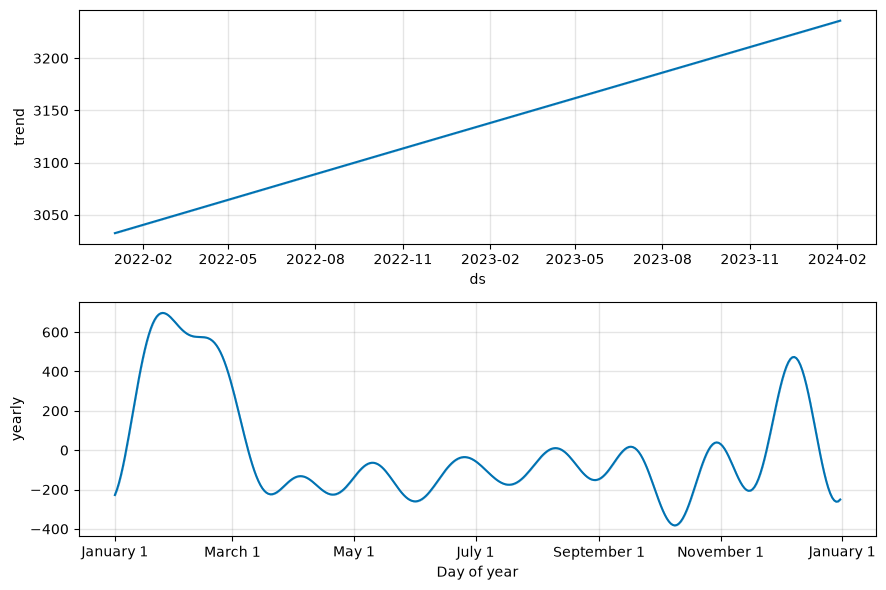

In [48]:
# Plot components (trend & yearly — all separated automatically)
fig = model.plot_components(prophet_pred)
plt.show()


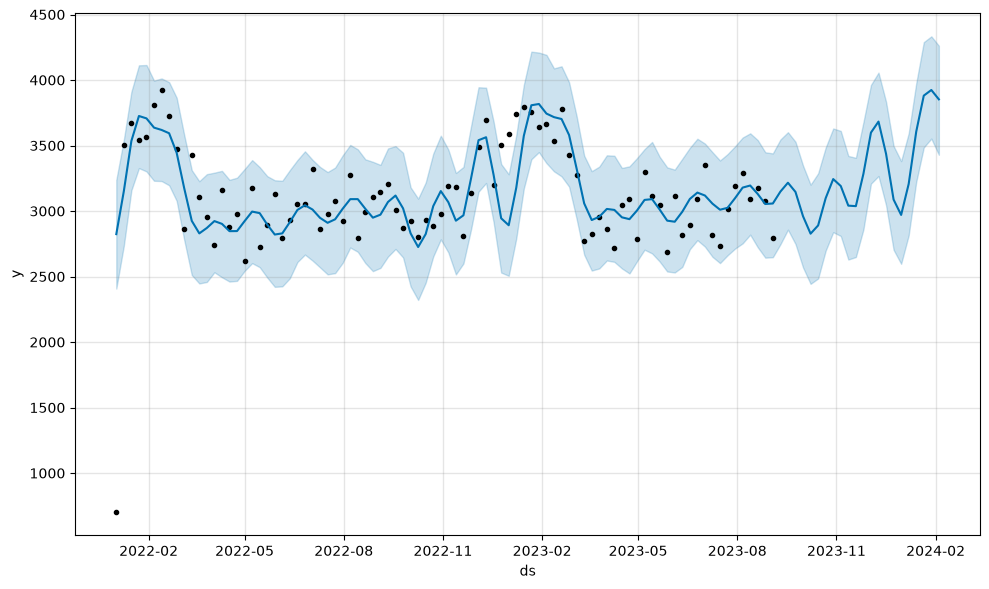

In [49]:
# Plot forecast vs actual
fig = model.plot(prophet_pred)
plt.show()


The graph illustrates Prophet's strong fit against historical weekly clothing sales, showing that actual data points fall consistently within the model's confidence intervals while capturing key yearly seasonal spikes. so as this model is perfect for deploying we are gonna merge the test train in a single dataset again adn then we will predict the unit sold from the last data of this dataset for 3 months.

In [50]:
# Merging test train 
prophet_df = full_data.reset_index()
prophet_df.columns = ['ds', 'y']

# Now fit the final model on 100% of the data
final_prophet = Prophet(yearly_seasonality=True,weekly_seasonality=False,daily_seasonality=False,seasonality_mode='additive')
final_prophet.fit(prophet_df)
# Create future dates for your operational horizon (e.g., next 12 weeks)
final_future = final_prophet.make_future_dataframe(periods=12, freq='W')
final_forecast = final_prophet.predict(final_future)

# Print your final operational forecasts with lower and upper bounds
print(final_forecast[['ds', 'yhat_lower', 'yhat', 'yhat_upper']].tail(12))

20:58:58 - cmdstanpy - INFO - Chain [1] start processing
20:58:58 - cmdstanpy - INFO - Chain [1] done processing


            ds   yhat_lower         yhat   yhat_upper
110 2024-02-11  2869.940654  3362.356733  3878.978701
111 2024-02-18  2998.908554  3558.499989  4077.927773
112 2024-02-25  3075.162515  3616.525112  4100.414303
113 2024-03-03  2923.079320  3408.211674  3912.380122
114 2024-03-10  2588.080275  3070.328180  3555.721337
115 2024-03-17  2317.961701  2853.814680  3381.418654
116 2024-03-24  2322.206291  2862.733217  3375.934166
117 2024-03-31  2448.623655  2974.477178  3504.427734
118 2024-04-07  2499.279615  3008.894855  3537.504003
119 2024-04-14  2407.405240  2932.314148  3431.146970
120 2024-04-21  2356.827211  2866.081552  3391.559076
121 2024-04-28  2436.019670  2914.585801  3414.683116


Finnaly we done with the full pipleline of time series forecasring with out 4 models ARIMA,SARIMAX,HOLT WINRER METHOD AND PROPHET and we can say that the winner is prophet/

NEXT TECHNIQUE - CLUSTERING

Product Clustering (Fast vs. Slow Movers)

In [74]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from kneed import KneeLocator

# 1. Group products by Product ID to find average demand (Units Sold) and price
product_summary = df.groupby('Product ID').agg({
    'Units Sold': 'mean',
    'Price': 'mean'
}).dropna()

# 2. Scale features so demand and price have equal weight
scaler = StandardScaler()
scaled_features = scaler.fit_transform(product_summary[['Units Sold', 'Price']])

# 3. To find the K value we will use The elbow method ( kneel locator for automatic k value)

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_) 

kl = KneeLocator(range(1,11), wcss, curve='convex', direction='decreasing')
best_k = kl.elbow


# 4. Now training a K-Means model

# a. Scale your features first — K-Means is distance-based
scaler = StandardScaler()
X = product_summary[['Units Sold', 'Price']]
X_scaled = scaler.fit_transform(X)

# b. Create the model with your chosen K (from Elbow/Silhouette results, not a guess)
model = KMeans(n_clusters=best_k, random_state=42)

# c. Fit it AND get cluster labels for every point, in one step
labels = model.fit_predict(X_scaled)

# d. Print the final answers
print("Cluster assigned to each point:", labels)
print("Centroid locations:", model.cluster_centers_)

# 5. evaluating output
# a. Attach cluster labels to your product_summary dataframe
product_summary['cluster'] = labels

# b. Map descriptive business names based on the cluster characteristics
# (Cluster with higher average units sold will be Fast Movers)
cluster_means = product_summary.groupby('cluster')[['Units Sold', 'Price']].mean()
print("=== Actual Averages per Cluster (Unscaled) ===")
print(cluster_means)

# c. View a sample of products with their assigned cluster names
print("\n=== Sample Product Segments ===")
print(product_summary[['Units Sold', 'Price', 'cluster']].head(19))

Cluster assigned to each point: [1 1 0 1 1 1 1 0 1 1 0 0 1 0 0 0 0 0 0 0]
Centroid locations: [[-0.7545016   0.63694242]
 [ 0.92216862 -0.77848518]]
=== Actual Averages per Cluster (Unscaled) ===
         Units Sold      Price
cluster                       
0         83.033149  82.005790
1         95.952477  50.262438

=== Sample Product Segments ===
            Units Sold       Price  cluster
Product ID                                 
P0001        93.927704   37.214425        1
P0002        94.562533   42.711850        1
P0003        89.831135   76.349858        0
P0004        99.435356   45.319219        1
P0005        92.581266   50.734240        1
P0006        90.686807   46.913018        1
P0007        99.973087   35.678377        1
P0008        85.096834   67.061908        0
P0009        99.182058   83.038807        1
P0010        94.013193   66.451950        1
P0011        87.619789   99.618113        0
P0012        77.916887   93.186330        0
P0013        99.210290   44.300

So here we can see that Cluster 1 captures your affordable, high-volume everyday items that fly off the shelves and need constant restocking, while Cluster 0 highlights your pricier items that sell at slightly lower volumes and require careful monitoring so they don't trap your cash.As by this we are ending up this Clustering pipline and moving towards our next model

Now our next model is Classification of "Will this product-day stock out (units sold above inventory level)?"
so lets make its pipeline

In [68]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# 1. 
#a Create the binary target column (1 if stock out, 0 otherwise)
df['stock_out'] = (df['Units Sold'] > df['Inventory Level']).astype(int)

#b Create lag features (grouped by Product ID so shifts stay within the same product)
df['lag_1'] = df.groupby('Product ID')['Units Sold'].shift(1)
df['lag_2'] = df.groupby('Product ID')['Units Sold'].shift(2)

# 2. Drop any rows where lag values are NaN (the first few days for each product)
df = df.dropna(subset=['lag_1', 'lag_2'])

# Set y
y2 = df['stock_out']

# Choose the columns that help predict a stock-out
features = [ 'Price', 'Inventory Level', 'lag_1', 'lag_2'] 
x2 = df[features]
# 2. Split your data
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(  x2, y2, test_size=0.2, random_state=42)

# 3a. Bagging example: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train_2, y_train_2)
rf_pred = rf_model.predict(X_test_2)
print("Random Forest predictions:", rf_pred)
print("Random Forest accuracy:", accuracy_score(y_test_2, rf_pred))

Random Forest predictions: [0 0 0 ... 0 0 0]
Random Forest accuracy: 1.0


ataset literally has zero stock-out events (meaning inventory was always enough to cover sales in this dataset), the model isn't broken—it's just being mathematically honest. It achieved 1.0 accuracy because it correctly figured out that guessing 0 every single time is always right for this data. So after this now we move forrward with our last but not the least model of this Mastered Projext which is Stock Planning


So our last Technique is Stock Planning which is very vital for the supply chain. As being the Supply Chain Analyst it is very vital to make the stock planning as accurate as possible so we will calculate Safety Stock and the Reorder Point (ROP)

In [73]:
# Calculate Average Demand and Demand Variability

lead_time_days = 5 # We only assuming our lead time is 5 days cause we do not have the column regarding it
z_score = 1.65  # 95% service level

# b. Grouping and Aggregating Data per Product
stock_planning = df.groupby('Product ID').agg(
     avg_daily_demand=('Units Sold', 'mean'),std_dev_demand=('Units Sold', 'std')).reset_index().fillna(0)
# c. Calculating Safety Stock
stock_planning['Safety_Stock'] = (z_score * stock_planning['std_dev_demand'] * np.sqrt(lead_time_days)).round(0)
# d. Calculating the Reorder Point (ROP)
stock_planning['Reorder_Point'] = ((stock_planning['avg_daily_demand'] * lead_time_days) + stock_planning['Safety_Stock']).round(0)
# e. Displaying the Result
print(stock_planning.head(19))

   Product ID  avg_daily_demand  std_dev_demand  Safety_Stock  Reorder_Point
0       P0001         93.927704       46.697994         172.0          642.0
1       P0002         94.562533       45.804479         169.0          642.0
2       P0003         89.831135       43.707007         161.0          610.0
3       P0004         99.435356       46.670268         172.0          669.0
4       P0005         92.581266       43.500289         160.0          623.0
5       P0006         90.686807       44.933243         166.0          619.0
6       P0007         99.973087       48.718834         180.0          680.0
7       P0008         85.096834       37.920328         140.0          565.0
8       P0009         99.182058       42.833762         158.0          654.0
9       P0010         94.013193       44.774451         165.0          635.0
10      P0011         87.619789       43.012170         159.0          597.0
11      P0012         77.916887       38.462819         142.0          532.0

Hence We can clearly see that what should be our safety stock adn what is our reorder point so it solve as massive supply chain problem to avoid eiter stockout or excessive inventory. From now here we are done with our Big project. 